# Assignment 2 — Autoencoder Anomaly Detection (MNIST)

This notebook runs the full pipeline required in the assignment:
- corruption of test images
- training autoencoders with MSE and SSIM
- reconstructions for clean and corrupted inputs
- deeper and convolutional variants
- anomaly detection with thresholding and confusion matrix


In [1]:
from pathlib import Path
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt


from data import (
    load_mnist,
    default_transforms,
    build_dataloaders,
    make_corrupted_subset,
    stratified_indices,
)
from models import SimpleAutoencoder, DeepAutoencoder, ConvAutoencoder
from training import train_autoencoder_sgd, evaluate_anomaly_detection, save_metrics_json
from visualization import (
    plot_original_corrupted,
    plot_reconstructions,
    plot_loss_curves,
    plot_loss_comparison,
    plot_error_distribution,
    plot_confusion_matrix,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# experiment settings
DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 120
BATCH_SIZE = 64
VAL_FRAC = 0.2
NOISE_LEVEL = 0.8
NOISE_TYPE = "gaussian"
CORRUPT_FRACTION = 0.1


device: cuda


/home/hhdel/repos/computerVision_3D_data/cv_assignment_2025_2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1) Corrupt 10% of test images and visualize


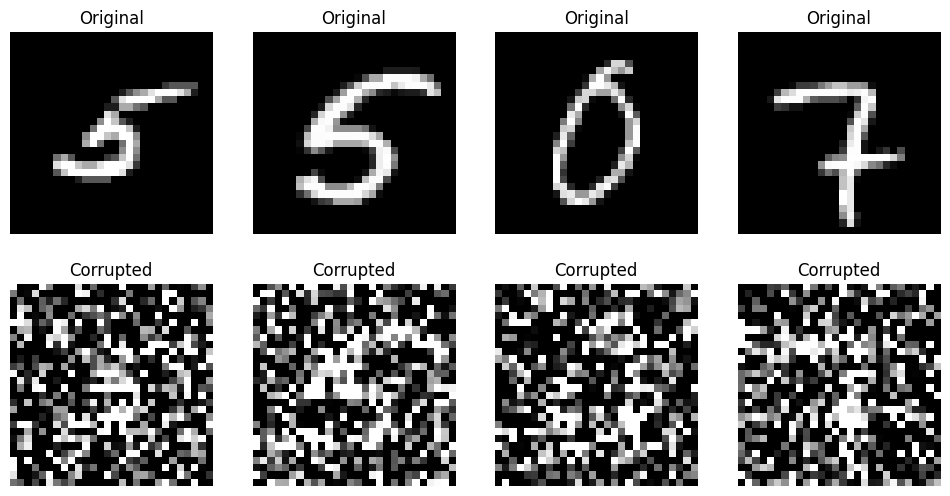

In [2]:
mnist_train, mnist_test = load_mnist(DATA_DIR)
transform_train, transform_val = default_transforms()

clean_ds, corrupt_ds = make_corrupted_subset(
    mnist_test,
    fraction=CORRUPT_FRACTION,
    noise_type=NOISE_TYPE,
    noise_level=NOISE_LEVEL,
)

plot_original_corrupted(
    clean_ds,
    corrupt_ds,
    n=4,
    save_path=OUTPUT_DIR / "corrupted_samples.png",
)


## 2) Build train/val loaders (stratified)


In [3]:
train_idx, val_idx = stratified_indices(mnist_train.targets, val_frac=VAL_FRAC)
train_loader, val_loader = build_dataloaders(
    mnist_train,
    train_idx,
    val_idx,
    batch_size=BATCH_SIZE,
    transform_train=transform_train,
    transform_val=transform_val,
    num_workers=4,
    pin_memory=True,
)


## 3) Train simple autoencoder with MSE + SGD


In [32]:
simple_model = SimpleAutoencoder()

history_simple_mse = train_autoencoder_sgd(
    simple_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    device=device,
    lr=0.2,
    loss_fn="mse",
)

simple_dir = OUTPUT_DIR / "simple_linear"
simple_dir.mkdir(parents=True, exist_ok=True)

torch.save(simple_model.state_dict(), simple_dir / "model_mse.pth")
save_metrics_json({"loss": history_simple_mse, "model": "simple_linear", "loss_name": "mse"}, simple_dir / "train_mse.json")

plot_loss_curves(
    history_simple_mse,
    title="Simple Autoencoder (MSE)",
    save_path=simple_dir / "train_mse.png",
)


Epoch 1/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 518.87it/s, loss=0.0731]


Epoch 1 | Train Loss: 0.189787 | Val Loss: 0.074376


Epoch 2/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 562.00it/s, loss=0.0712]


Epoch 2 | Train Loss: 0.070747 | Val Loss: 0.069755


Epoch 3/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 564.68it/s, loss=0.0695]


Epoch 3 | Train Loss: 0.069291 | Val Loss: 0.068946


... (230 outputs left out)

Epoch 119/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 559.34it/s, loss=0.0201]


Epoch 119 | Train Loss: 0.021293 | Val Loss: 0.021334


Epoch 120/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 576.02it/s, loss=0.02]  


Epoch 120 | Train Loss: 0.021165 | Val Loss: 0.021205


## 4) Reconstructions: clean vs corrupted


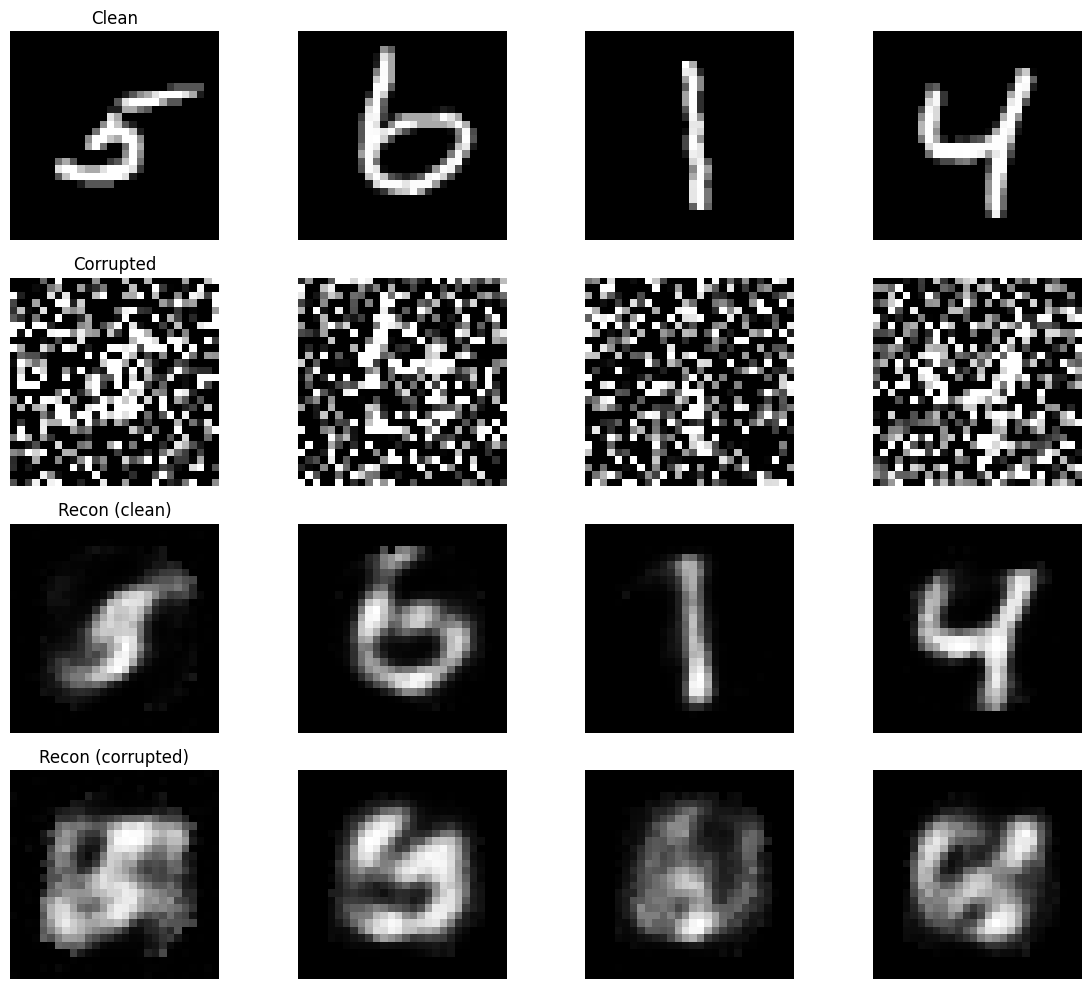

In [33]:
# Show clean, corrupted, recon(clean), recon(corrupted)

repo = Path.cwd()
OUTPUT_DIR = Path("output")
ckpt_path = OUTPUT_DIR / "simple_linear" / "model_mse.pth"

# Load SSIM model
model = SimpleAutoencoder().to(device)
state = torch.load(ckpt_path, map_location=device)
model.load_state_dict(state)
model.eval()

# Pick 4 samples
idx = torch.linspace(0, len(clean_ds) - 1, steps=4).long().tolist()
clean_imgs = torch.stack([clean_ds[i][0] for i in idx]).to(device)
corrupt_imgs = torch.stack([corrupt_ds[i][0] for i in idx]).to(device)

with torch.no_grad():
    recon_clean = model(clean_imgs)
    recon_corrupt = model(corrupt_imgs)

# Reshape if needed
if recon_clean.ndim == 2:
    recon_clean = recon_clean.view(-1, 1, 28, 28)
    recon_corrupt = recon_corrupt.view(-1, 1, 28, 28)

rows = [clean_imgs, corrupt_imgs, recon_clean, recon_corrupt]
labels = ["Clean", "Corrupted", "Recon (clean)", "Recon (corrupted)"]

plt.figure(figsize=(12, 10))
for r, row in enumerate(rows):
    for c in range(4):
        ax = plt.subplot(4, 4, r * 4 + c + 1)
        ax.imshow(row[c].detach().cpu().squeeze(), cmap="gray")
        ax.axis("off")
        if c == 0:
            ax.set_title(labels[r])
plt.tight_layout()
plt.show()


## 5) SSIM loss vs MSE (Simple Autoencoder)


In [34]:
ssim_model = SimpleAutoencoder()

history_simple_ssim = train_autoencoder_sgd(
    ssim_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    device=device,
    lr=0.2,
    loss_fn="ssim",
)

torch.save(ssim_model.state_dict(), simple_dir / "model_ssim.pth")
save_metrics_json({"loss": history_simple_ssim, "model": "simple_linear", "loss_name": "ssim"}, simple_dir / "train_ssim.json")

plot_loss_comparison(
    history_simple_mse,
    history_simple_ssim,
    save_path=simple_dir / "loss_mse_vs_ssim.png",
)


Epoch 1/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 428.69it/s, loss=0.523]


Epoch 1 | Train Loss: 0.687916 | Val Loss: 0.524101


Epoch 2/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 439.39it/s, loss=0.499]


Epoch 2 | Train Loss: 0.515354 | Val Loss: 0.498706


Epoch 3/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 441.09it/s, loss=0.417]


Epoch 3 | Train Loss: 0.455340 | Val Loss: 0.422162


... (230 outputs left out)

Epoch 119/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 421.64it/s, loss=0.0658]


Epoch 119 | Train Loss: 0.063595 | Val Loss: 0.064555


Epoch 120/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 443.69it/s, loss=0.0606]


Epoch 120 | Train Loss: 0.063441 | Val Loss: 0.064836


## 6) Reconstructions: clean vs corrupted for SSIM model

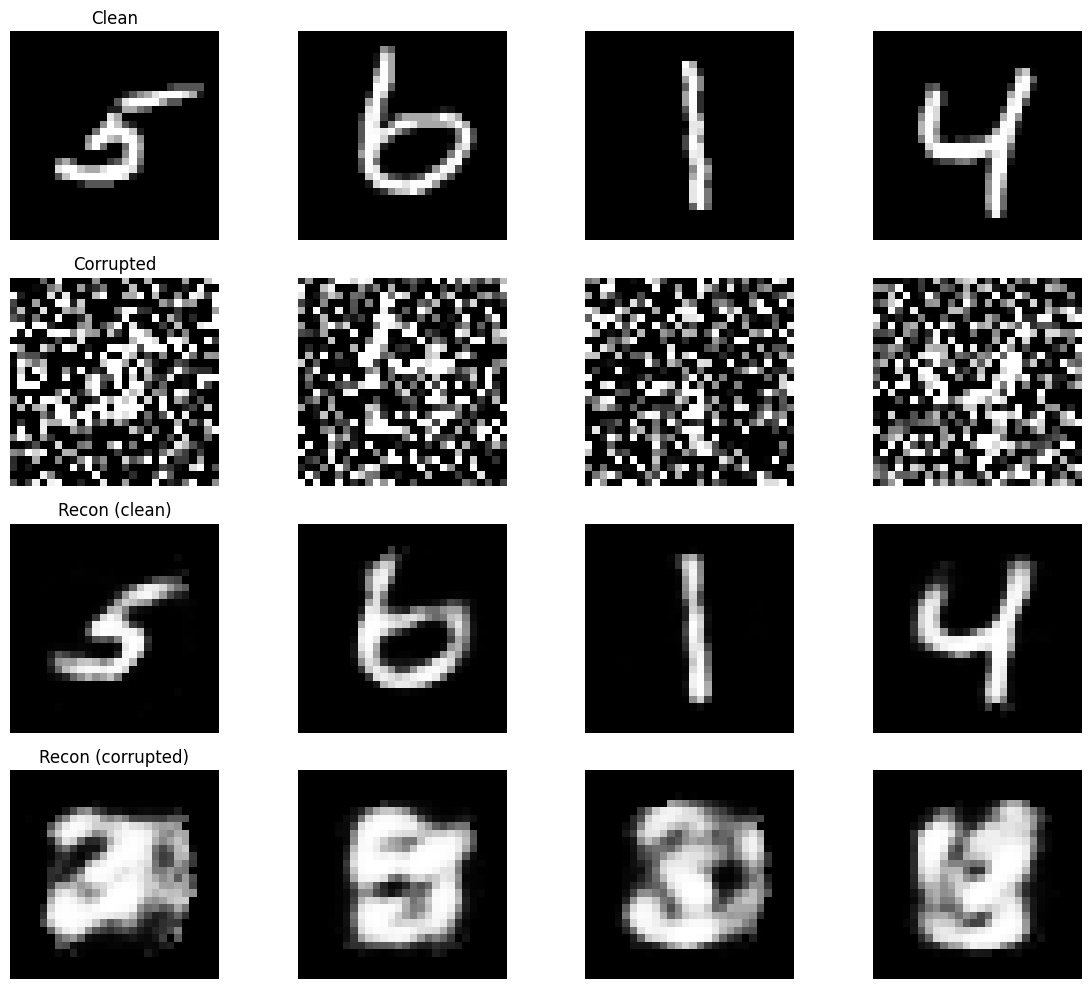

In [35]:
# Paths
# from pathlib import Path

repo = Path.cwd()
OUTPUT_DIR = Path("output")
ckpt_path = OUTPUT_DIR / "simple_linear" / "model_ssim.pth"

# Load SSIM model
model = SimpleAutoencoder().to(device)
state = torch.load(ckpt_path, map_location=device)
model.load_state_dict(state)
model.eval()

# Pick 4 samples
idx = torch.linspace(0, len(clean_ds) - 1, steps=4).long().tolist()
clean_imgs = torch.stack([clean_ds[i][0] for i in idx]).to(device)
corrupt_imgs = torch.stack([corrupt_ds[i][0] for i in idx]).to(device)

with torch.no_grad():
    recon_clean = model(clean_imgs)
    recon_corrupt = model(corrupt_imgs)

# Reshape if needed
if recon_clean.ndim == 2:
    recon_clean = recon_clean.view(-1, 1, 28, 28)
    recon_corrupt = recon_corrupt.view(-1, 1, 28, 28)

rows = [clean_imgs, corrupt_imgs, recon_clean, recon_corrupt]
labels = ["Clean", "Corrupted", "Recon (clean)", "Recon (corrupted)"]

plt.figure(figsize=(12, 10))
for r, row in enumerate(rows):
    for c in range(4):
        ax = plt.subplot(4, 4, r * 4 + c + 1)
        ax.imshow(row[c].detach().cpu().squeeze(), cmap="gray")
        ax.axis("off")
        if c == 0:
            ax.set_title(labels[r])
plt.tight_layout()
plt.show()


## 6) Deep autoencoder


In [36]:
deep_model = DeepAutoencoder()

deep_history = train_autoencoder_sgd(
    deep_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    device=device,
    lr=0.2,
    loss_fn="mse",
)

deep_dir = OUTPUT_DIR / "deep_linear"
deep_dir.mkdir(parents=True, exist_ok=True)

torch.save(deep_model.state_dict(), deep_dir / "model_mse.pth")
save_metrics_json({"loss": deep_history, "model": "deep_linear", "loss_name": "mse"}, deep_dir / "train_mse.json")

plot_loss_curves(deep_history, title="Deep Autoencoder (MSE)", save_path=deep_dir / "train_mse.png")
plot_reconstructions(deep_model, clean_ds, corrupt_ds, device=device, n=4, save_path=deep_dir / "reconstructions.png")


Epoch 1/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 417.61it/s, loss=0.191]


Epoch 1 | Train Loss: 0.220686 | Val Loss: 0.190526


Epoch 2/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 417.13it/s, loss=0.0729]


Epoch 2 | Train Loss: 0.087174 | Val Loss: 0.067702


Epoch 3/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 423.07it/s, loss=0.0625]


Epoch 3 | Train Loss: 0.067480 | Val Loss: 0.067427


... (230 outputs left out)

Epoch 119/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 417.81it/s, loss=0.0487]


Epoch 119 | Train Loss: 0.043820 | Val Loss: 0.043913


Epoch 120/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 420.97it/s, loss=0.0448]


Epoch 120 | Train Loss: 0.043685 | Val Loss: 0.043984


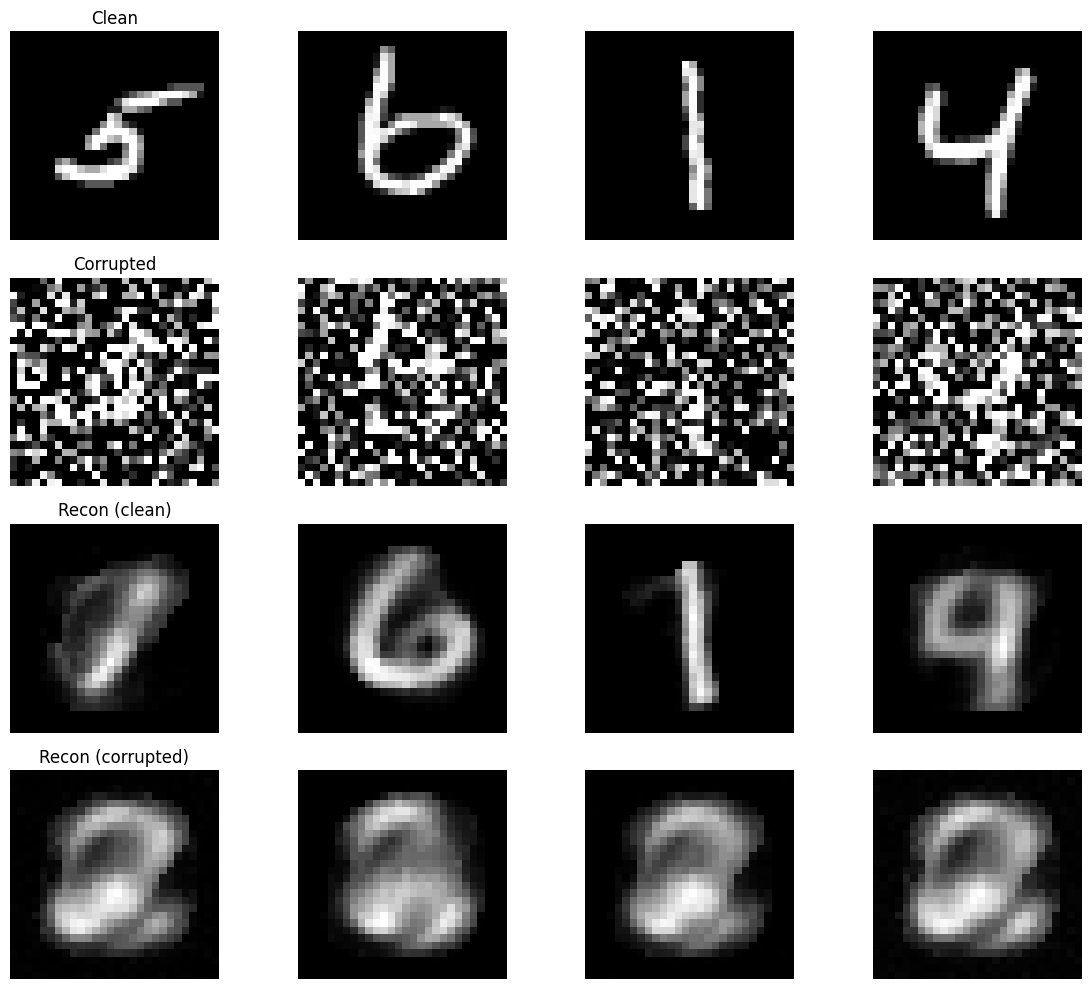

In [37]:
repo = Path.cwd()
OUTPUT_DIR = Path("output")
ckpt_path = OUTPUT_DIR / "deep_linear" / "model_mse.pth"

# Load SSIM model
model = DeepAutoencoder().to(device)
state = torch.load(ckpt_path, map_location=device)
model.load_state_dict(state)
model.eval()

# Pick 4 samples
idx = torch.linspace(0, len(clean_ds) - 1, steps=4).long().tolist()
clean_imgs = torch.stack([clean_ds[i][0] for i in idx]).to(device)
corrupt_imgs = torch.stack([corrupt_ds[i][0] for i in idx]).to(device)

with torch.no_grad():
    recon_clean = model(clean_imgs)
    recon_corrupt = model(corrupt_imgs)

# Reshape if needed
if recon_clean.ndim == 2:
    recon_clean = recon_clean.view(-1, 1, 28, 28)
    recon_corrupt = recon_corrupt.view(-1, 1, 28, 28)

rows = [clean_imgs, corrupt_imgs, recon_clean, recon_corrupt]
labels = ["Clean", "Corrupted", "Recon (clean)", "Recon (corrupted)"]

plt.figure(figsize=(12, 10))
for r, row in enumerate(rows):
    for c in range(4):
        ax = plt.subplot(4, 4, r * 4 + c + 1)
        ax.imshow(row[c].detach().cpu().squeeze(), cmap="gray")
        ax.axis("off")
        if c == 0:
            ax.set_title(labels[r])
plt.tight_layout()
plt.show()

## 7) Convolutional autoencoder


In [38]:
conv_model = ConvAutoencoder()

conv_history = train_autoencoder_sgd(
    conv_model,
    train_loader,
    val_loader,
    epochs=EPOCHS,
    device=device,
    lr=0.1,
    loss_fn="mse",
)

conv_dir = OUTPUT_DIR / "conv"
conv_dir.mkdir(parents=True, exist_ok=True)

torch.save(conv_model.state_dict(), conv_dir / "model_mse.pth")
save_metrics_json({"loss": conv_history, "model": "conv", "loss_name": "mse"}, conv_dir / "train_mse.json")

plot_loss_curves(conv_history, title="Conv Autoencoder (MSE)", save_path=conv_dir / "train_mse.png")
plot_reconstructions(conv_model, clean_ds, corrupt_ds, device=device, n=4, save_path=conv_dir / "reconstructions.png")


Epoch 1/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 488.26it/s, loss=0.0927]


Epoch 1 | Train Loss: 0.101605 | Val Loss: 0.094979


Epoch 2/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 488.95it/s, loss=0.0871]


Epoch 2 | Train Loss: 0.095031 | Val Loss: 0.094894


Epoch 3/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 496.42it/s, loss=0.0962]


Epoch 3 | Train Loss: 0.094989 | Val Loss: 0.094864


... (230 outputs left out)

Epoch 119/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 483.74it/s, loss=0.00664]


Epoch 119 | Train Loss: 0.006166 | Val Loss: 0.006190


Epoch 120/120 [Train]: 100%|██████████| 750/750 [00:01<00:00, 496.87it/s, loss=0.00677]


Epoch 120 | Train Loss: 0.006128 | Val Loss: 0.006175


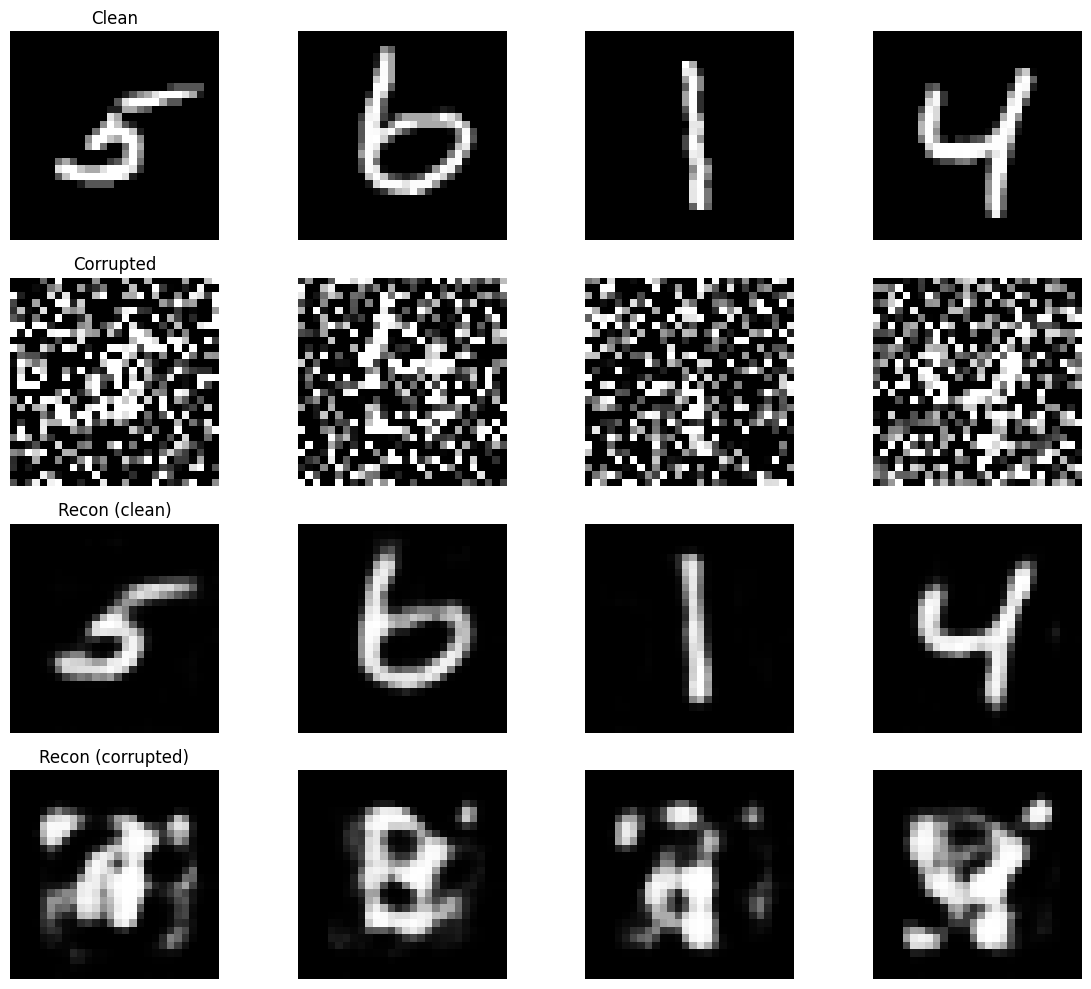

In [39]:
repo = Path.cwd()
OUTPUT_DIR = Path("output")
ckpt_path = OUTPUT_DIR / "conv" / "model_mse.pth"

# Load SSIM model
model = ConvAutoencoder().to(device)
state = torch.load(ckpt_path, map_location=device)
model.load_state_dict(state)
model.eval()

# Pick 4 samples
idx = torch.linspace(0, len(clean_ds) - 1, steps=4).long().tolist()
clean_imgs = torch.stack([clean_ds[i][0] for i in idx]).to(device)
corrupt_imgs = torch.stack([corrupt_ds[i][0] for i in idx]).to(device)

with torch.no_grad():
    recon_clean = model(clean_imgs)
    recon_corrupt = model(corrupt_imgs)

# Reshape if needed
if recon_clean.ndim == 2:
    recon_clean = recon_clean.view(-1, 1, 28, 28)
    recon_corrupt = recon_corrupt.view(-1, 1, 28, 28)

rows = [clean_imgs, corrupt_imgs, recon_clean, recon_corrupt]
labels = ["Clean", "Corrupted", "Recon (clean)", "Recon (corrupted)"]

plt.figure(figsize=(12, 10))
for r, row in enumerate(rows):
    for c in range(4):
        ax = plt.subplot(4, 4, r * 4 + c + 1)
        ax.imshow(row[c].detach().cpu().squeeze(), cmap="gray")
        ax.axis("off")
        if c == 0:
            ax.set_title(labels[r])
plt.tight_layout()
plt.show()

## 8) Select the best model (lowest val loss) and run anomaly detection


In [51]:
# 7) Choose best model by anomaly-detection F1 and run thresholding
models = {
  "simple_mse": simple_model,
  "simple_ssim": ssim_model,
  "deep_mse": deep_model,
  "conv_mse": conv_model,
}

# NEW: override corruption level just for anomaly evaluation (tune this to create overlap)
ANOMALY_NOISE_LEVEL = 0.4  # try 0.4–0.8

from data import corrupt_images  # uses same corruption function as before
corrupt_ds_eval = torch.utils.data.TensorDataset(
    corrupt_images(clean_ds.tensors[0], noise_type=NOISE_TYPE, noise_level=ANOMALY_NOISE_LEVEL),
    clean_ds.tensors[1],
)

clean_loader = torch.utils.data.DataLoader(clean_ds, batch_size=BATCH_SIZE, shuffle=False)
corrupt_loader = torch.utils.data.DataLoader(corrupt_ds_eval, batch_size=BATCH_SIZE, shuffle=False)

metrics_by_model = {}
errors_by_model = {}
for name, model in models.items():
    metrics, clean_errors, corrupt_errors = evaluate_anomaly_detection(
        model,
        clean_loader,
        corrupt_loader,
        device=device,
    )
    metrics_by_model[name] = metrics
    errors_by_model[name] = (clean_errors, corrupt_errors)

best_name = max(metrics_by_model, key=lambda k: metrics_by_model[k]["f1"])
best_metrics = metrics_by_model[best_name]
print("Best model by F1:", best_name)

save_metrics_json(
    {"best_model": best_name, "all_metrics": metrics_by_model},
    OUTPUT_DIR / "anomaly_metrics.json",
)

best_clean_errors, best_corrupt_errors = errors_by_model[best_name]
plot_error_distribution(
    best_clean_errors.numpy(),
    best_corrupt_errors.numpy(),
    threshold=best_metrics["threshold"],
    save_path=OUTPUT_DIR / "error_distribution.png",
)

cm = np.array([
    [best_metrics["tn"], best_metrics["fp"]],
    [best_metrics["fn"], best_metrics["tp"]],
])
plot_confusion_matrix(cm, save_path=OUTPUT_DIR / "confusion_matrix.png")


Best model by F1: simple_mse


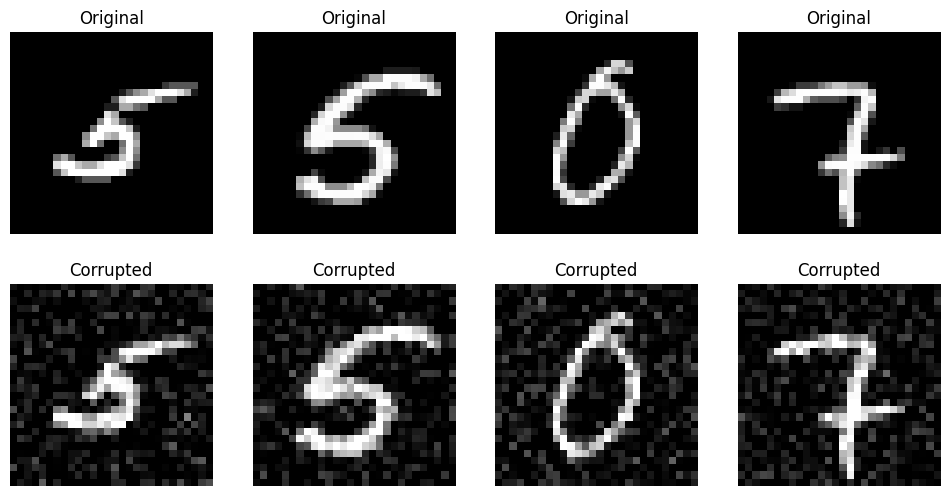

Anomaly noise level: 0.14
Best model by F1: conv_mse
Best metrics: {'threshold': 0.010679467570735143, 'tp': 984, 'tn': 920, 'fp': 80, 'fn': 16, 'precision': 0.924812030075188, 'recall': 0.984, 'f1': 0.9534883720930233, 'threshold_method': 'f1'}


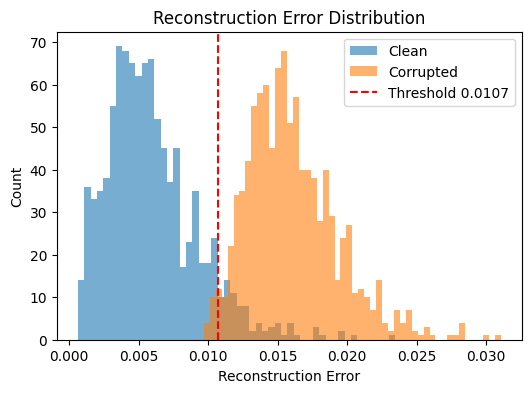


Confusion matrix (rows=true [clean,corrupt], cols=pred [clean,corrupt]):
[[920  80]
 [ 16 984]]


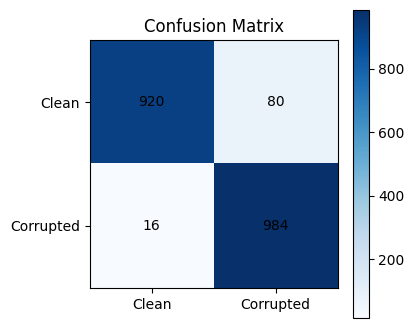

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from data import corrupt_images
from visualization import plot_original_corrupted

# Load models from saved checkpoints in case of a fresh script run
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUTPUT_DIR = Path("output")

simple_mse = SimpleAutoencoder().to(device)
simple_mse.load_state_dict(torch.load(OUTPUT_DIR / "simple_linear" / "model_mse.pth", map_location=device))
simple_mse.eval()

simple_ssim = SimpleAutoencoder().to(device)
simple_ssim.load_state_dict(torch.load(OUTPUT_DIR / "simple_linear" / "model_ssim.pth", map_location=device))
simple_ssim.eval()

deep_mse = DeepAutoencoder().to(device)
deep_mse.load_state_dict(torch.load(OUTPUT_DIR / "deep_linear" / "model_mse.pth", map_location=device))
deep_mse.eval()

conv_mse = ConvAutoencoder().to(device)
conv_mse.load_state_dict(torch.load(OUTPUT_DIR / "conv" / "model_mse.pth", map_location=device))
conv_mse.eval()


# 7) Choose best model by anomaly-detection F1 and run thresholding

models = {
  "simple_mse": simple_mse,
  "simple_ssim": simple_ssim,
  "deep_mse": deep_mse,
  "conv_mse": conv_mse,
}


for m in models.values():
    m.to(device)
    m.eval()


ANOMALY_NOISE_LEVEL = 0.14 

corrupt_ds_eval = torch.utils.data.TensorDataset(
    corrupt_images(clean_ds.tensors[0], noise_type=NOISE_TYPE, noise_level=ANOMALY_NOISE_LEVEL),
    clean_ds.tensors[1],
)

# Plot the newly corrupted images (clean vs new-corrupted)
plot_original_corrupted(clean_ds, corrupt_ds_eval, n=4, save_path=None)

clean_loader = torch.utils.data.DataLoader(clean_ds, batch_size=BATCH_SIZE, shuffle=False)
corrupt_loader = torch.utils.data.DataLoader(corrupt_ds_eval, batch_size=BATCH_SIZE, shuffle=False)

metrics_by_model = {}
errors_by_model = {}
for name, model in models.items():
    metrics, clean_errors, corrupt_errors = evaluate_anomaly_detection(
        model,
        clean_loader,
        corrupt_loader,
        device=device,
    )
    metrics_by_model[name] = metrics
    errors_by_model[name] = (clean_errors, corrupt_errors)

# pick best by F1 ("accuracy results")
best_name = max(metrics_by_model, key=lambda k: metrics_by_model[k]["f1"])
best_metrics = metrics_by_model[best_name]
print("Anomaly noise level:", ANOMALY_NOISE_LEVEL)
print("Best model by F1:", best_name)
print("Best metrics:", best_metrics)

save_metrics_json(
    {"best_model": best_name, "all_metrics": metrics_by_model},
    OUTPUT_DIR / "anomaly_metrics.json",
)

best_clean_errors, best_corrupt_errors = errors_by_model[best_name]

err_path = OUTPUT_DIR / "error_distribution.png"
cm_path  = OUTPUT_DIR / "confusion_matrix.png"

plot_error_distribution(
    best_clean_errors.numpy(),
    best_corrupt_errors.numpy(),
    threshold=best_metrics["threshold"],
    save_path=err_path,
)

cm = np.array([
    [best_metrics["tn"], best_metrics["fp"]],
    [best_metrics["fn"], best_metrics["tp"]],
])
print("\nConfusion matrix (rows=true [clean,corrupt], cols=pred [clean,corrupt]):")
print(cm)

plot_confusion_matrix(cm, save_path=cm_path)
plt.show()
